# 07 - Tests statistiques complémentaires (critère 1.2)

Le notebook 01 réalise 2 tests (Mann-Whitney U sur `Rating`, χ² sur `Department Name`). Le barème exige **au moins 2 tests avec justification** ;
pour sécuriser les 3 points on en ajoute d'autres, dont un **test de normalité** qui justifie le choix des tests non paramétriques.

| # | Test | Question | Pourquoi ce test |
|---|------|----------|------------------|
| T1 | Shapiro-Wilk | `Age` et `Rating` suivent-ils une loi normale ? | Décide entre tests paramétriques et non paramétriques |
| T2 | Mann-Whitney U | `Age` diffère-t-il selon la recommandation ? | Variable quantitative non normale, 2 groupes indépendants |
| T3 | Mann-Whitney U | `Rating` diffère-t-il selon la recommandation ? | Variable ordinale, 2 groupes indépendants (repris du notebook 01) |
| T4 | Kruskal-Wallis | `Rating` diffère-t-il selon le département ? | Plus de 2 groupes, variable ordinale (alternative à l'ANOVA) |
| T5 | Spearman | `Age` et `Positive Feedback Count` sont-ils corrélés ? | Relation monotone, pas de normalité requise |
| T6 | Spearman | La longueur de l'avis est-elle liée à la note ? | Idem |
| T7 | χ² d'indépendance | `Class Name` est-il associé à la recommandation ? | Deux variables qualitatives |

Les p-values sont corrigées pour les tests multiples (Benjamini-Hochberg, FDR) et chaque test est accompagné d'une **taille d'effet** :
avec plus de 23 000 observations, presque tout est « significatif » ; seule la taille d'effet dit si la différence compte vraiment.

## 1. Configuration

In [ ]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
from ml_utils import load_clean_data, TARGET, RANDOM_STATE

FIG_DIR = ROOT / "docs" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR = ROOT / "reports"; REPORT_DIR.mkdir(parents=True, exist_ok=True)

df = load_clean_data()
df["Review Length"] = df["Review Text"].astype(str).str.split().str.len()
ALPHA = 0.05
rows = []
print(df.shape)

(23465, 11)


## 2. T1 - Shapiro-Wilk : normalité de `Age` et `Rating`

H0 : la variable suit une loi normale. Shapiro-Wilk est calculé sur un échantillon de 5 000 observations (limite de fiabilité de l'implémentation SciPy).
On complète avec un diagramme quantile-quantile.

Age      W = 0.9753  p = 1.44e-28  -> normalité rejetée
Rating   W = 0.7353  p = 5.32e-67  -> normalité rejetée


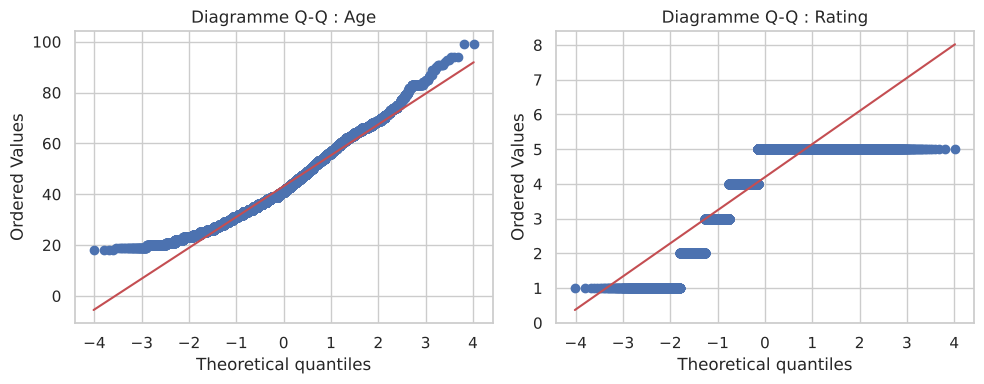

In [ ]:
sample = df.sample(5000, random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ["Age", "Rating"]):
    w, p = stats.shapiro(sample[col])
    rows.append({"Test": "T1 Shapiro-Wilk", "Variables": col, "Statistique": w, "p-value": p,
                 "Taille d'effet": np.nan, "Type d'effet": "-", "Justification": "Normalité : décide paramétrique vs non paramétrique"})
    print(f"{col:<8} W = {w:.4f}  p = {p:.3g}  ->", "normalité rejetée" if p < ALPHA else "normalité non rejetée")
    stats.probplot(df[col], dist="norm", plot=ax)
    ax.set_title(f"Diagramme Q-Q : {col}")
fig.tight_layout(); fig.savefig(FIG_DIR / "qq_plots.png", dpi=200); plt.show()

**Lecture** : la normalité est rejetée (p ≪ 0,05) et `Rating` est une variable ordinale à 5 niveaux. On utilise donc des tests **non paramétriques** (Mann-Whitney, Kruskal-Wallis, Spearman) plutôt que le test t, l'ANOVA ou Pearson.

## 3. T2 et T3 - Mann-Whitney U : `Age` et `Rating` selon la recommandation

Age     U = 42,136,250  p = 1.86e-06  r = +0.047
Rating  U = 78,256,892  p = 0  r = +0.945


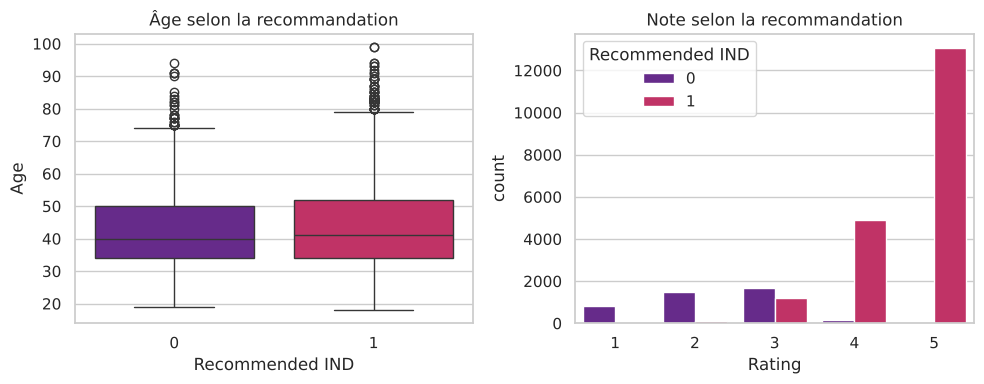

In [ ]:
def mann_whitney(col):
    a = df.loc[df[TARGET] == 1, col]; b = df.loc[df[TARGET] == 0, col]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    r = 2 * u / (len(a) * len(b)) - 1      # corrélation bisériale par rangs : > 0 si le groupe « recommandé » a des valeurs plus élevées
    return u, p, r

for col, tid in [("Age", "T2"), ("Rating", "T3")]:
    u, p, r = mann_whitney(col)
    rows.append({"Test": f"{tid} Mann-Whitney U", "Variables": f"{col} vs {TARGET}", "Statistique": u, "p-value": p,
                 "Taille d'effet": r, "Type d'effet": "r bisérial par rangs",
                 "Justification": "2 groupes indépendants, variable non normale/ordinale"})
    print(f"{col:<7} U = {u:,.0f}  p = {p:.3g}  r = {r:+.3f}")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(data=df, x=TARGET, y="Age", palette=["#6A1B9A", "#D81B60"], ax=axes[0])
sns.countplot(data=df, x="Rating", hue=TARGET, palette=["#6A1B9A", "#D81B60"], ax=axes[1])
axes[0].set_title("Âge selon la recommandation"); axes[1].set_title("Note selon la recommandation")
fig.tight_layout(); fig.savefig(FIG_DIR / "mann_whitney.png", dpi=200); plt.show()

## 4. T4 - Kruskal-Wallis : `Rating` selon le département

In [ ]:
groups = [g["Rating"].values for _, g in df[df["Department Name"] != "Unknown"].groupby("Department Name")]
h, p = stats.kruskal(*groups)
n = sum(len(g) for g in groups)
eps2 = (h - len(groups) + 1) / (n - len(groups))   # epsilon² : proportion de variance expliquée par les rangs
rows.append({"Test": "T4 Kruskal-Wallis", "Variables": "Rating vs Department Name", "Statistique": h, "p-value": p,
             "Taille d'effet": eps2, "Type d'effet": "epsilon²",
             "Justification": "Plus de 2 groupes, variable ordinale (alternative non paramétrique à l'ANOVA)"})
print(f"H = {h:.2f}  p = {p:.3g}  epsilon² = {eps2:.4f}")

H = 79.12  p = 1.28e-15  epsilon² = 0.0032


## 5. T5 et T6 - Corrélations de Spearman

In [ ]:
for (a, b), tid in [(("Age", "Positive Feedback Count"), "T5"), (("Review Length", "Rating"), "T6")]:
    rho, p = stats.spearmanr(df[a], df[b])
    rows.append({"Test": f"{tid} Spearman", "Variables": f"{a} vs {b}", "Statistique": rho, "p-value": p,
                 "Taille d'effet": rho, "Type d'effet": "rho de Spearman",
                 "Justification": "Relation monotone entre deux variables non normales"})
    print(f"{a} vs {b}: rho = {rho:+.3f}  p = {p:.3g}")

Age vs Positive Feedback Count: rho = +0.075  p = 5.42e-31
Review Length vs Rating: rho = -0.091  p = 1.3e-44


## 6. T7 - χ² d'indépendance : `Class Name` et recommandation

In [ ]:
ct = pd.crosstab(df["Class Name"], df[TARGET])
ct = ct[ct.sum(axis=1) >= 30]   # on écarte les modalités trop rares (effectif théorique < 5)
chi2, p, dof, expected = stats.chi2_contingency(ct)
cramer = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
rows.append({"Test": "T7 Chi-deux", "Variables": f"Class Name vs {TARGET}", "Statistique": chi2, "p-value": p,
             "Taille d'effet": cramer, "Type d'effet": "V de Cramér",
             "Justification": "Deux variables qualitatives, effectifs théoriques >= 5"})
print(f"chi2 = {chi2:.2f}  ddl = {dof}  p = {p:.3g}  V de Cramér = {cramer:.3f}  (min effectif théorique = {expected.min():.1f})")

chi2 = 75.43  ddl = 17  p = 2.45e-09  V de Cramér = 0.057  (min effectif théorique = 21.2)


## 7. Synthèse avec correction des tests multiples (Benjamini-Hochberg)

In [ ]:
def bh_adjust(pvals):
    p = np.asarray(pvals, float); n = len(p)
    order = np.argsort(p); ranked = p[order] * n / (np.arange(n) + 1)
    adj = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty(n); out[order] = np.minimum(adj, 1.0)
    return out

tests = pd.DataFrame(rows)
tests["p-value ajustée (BH)"] = bh_adjust(tests["p-value"])
tests["Décision (α = 0,05)"] = np.where(tests["p-value ajustée (BH)"] < ALPHA, "Rejet de H0", "Non-rejet de H0")
tests.loc[tests["Test"].str.startswith("T1"), "Décision (α = 0,05)"] = np.where(
    tests.loc[tests["Test"].str.startswith("T1"), "p-value ajustée (BH)"] < ALPHA, "Non normal", "Normal")
tests.to_csv(REPORT_DIR / "stat_tests.csv", index=False)
shown = tests.drop(columns=["Justification"]).copy()
shown["p-value"] = shown["p-value"].map("{:.2e}".format)
shown["p-value ajustée (BH)"] = shown["p-value ajustée (BH)"].map("{:.2e}".format)
display(shown.round(4))

,Test,Variables,Statistique,p-value,Taille d'effet,Type d'effet,p-value ajustée (BH),"Décision (α = 0,05)"
0,T1 Shapiro-Wilk,Age,9.753000e-01,1.44e-28,NaN,-,2.30e-28,Non normal
1,T1 Shapiro-Wilk,Rating,7.353000e-01,5.32e-67,NaN,-,2.13e-66,Non normal
2,T2 Mann-Whitney U,Age vs Recommended IND,4.213625e+07,1.86e-06,0.0470,r bisérial par rangs,1.86e-06,Rejet de H0
3,T3 Mann-Whitney U,Rating vs Recommended IND,7.825689e+07,0.00e+00,0.9445,r bisérial par rangs,0.00e+00,Rejet de H0
4,T4 Kruskal-Wallis,Rating vs Department Name,7.912050e+01,1.28e-15,0.0032,epsilon²,1.71e-15,Rejet de H0
5,T5 Spearman,Age vs Positive Feedback Count,7.550000e-02,5.42e-31,0.0755,rho de Spearman,1.08e-30,Rejet de H0
6,T6 Spearman,Review Length vs Rating,-9.130000e-02,1.30e-44,-0.0913,rho de Spearman,3.47e-44,Rejet de H0
7,T7 Chi-deux,Class Name vs Recommended IND,7.543280e+01,2.45e-09,0.0567,V de Cramér,2.80e-09,Rejet de H0


**À rédiger dans le rapport** : pour chaque test, rappeler H0/H1, justifier le test (type de variables, normalité, indépendance des groupes),
donner la statistique, la p-value ajustée **et la taille d'effet**, puis conclure en langage métier. Exemple : « la note est très fortement associée
à la recommandation (r bisérial élevé) alors que l'âge l'est très faiblement : à effectif égal, la note est un bien meilleur prédicteur que l'âge. »